![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# The ML Workflow End to End
*Data Science & Machine Learning - Week 5, Day 4*

## How to use this notebook

This week you learned the pieces one at a time: pipelines and grid search on Day 1, ensembles on Day 2, unsupervised methods on Day 3. Today you put the supervised pieces together into **one workflow, start to finish**, in the order you would follow on a real project, and on Project 2:

1. **Frame the problem**: what to predict, which class is positive, which mistakes cost most, and which metric reflects that.
2. **Look at the data**, briefly.
3. **Split once**, and put the test set away.
4. **Set a baseline** that any real model must beat.
5. **Build pipelines**, so every preprocessing step is learned from training data only.
6. **Compare candidate models** with cross-validation.
7. **Tune** the most promising ones.
8. **Choose a decision threshold** that fits the cost of each mistake.
9. **Evaluate once** on the test set.
10. **Interpret** the model.
11. **Save it, reload it and predict** for new cases.

The example is the breast cancer dataset built into scikit-learn, so there is nothing to download. The appendix runs the same template on data with text categories, and shows what goes wrong when a step is done outside the pipeline. Run the cells in order.

## Table of contents

- [Setup](#Setup)
- [1. Frame the problem](#1.-Frame-the-problem)
- [2. Look at the data](#2.-Look-at-the-data)
- [3. Split once](#3.-Split-once)
- [4. Set a baseline](#4.-Set-a-baseline)
- [5. Build pipelines](#5.-Build-pipelines)
- [6. Compare candidates with cross-validation](#6.-Compare-candidates-with-cross-validation)
- [7. Tune the most promising models](#7.-Tune-the-most-promising-models)
- [8. Choose a decision threshold](#8.-Choose-a-decision-threshold)
- [9. Evaluate once on the test set](#9.-Evaluate-once-on-the-test-set)
- [10. Interpret the model](#10.-Interpret-the-model)
- [11. Save, reload and predict](#11.-Save,-reload-and-predict)
- [Summary: the template](#Summary:-the-template)
- [Appendix](#Appendix)
    - [A.1 The same template with mixed column types](#A.1-The-same-template-with-mixed-column-types)
    - [A.2 Leakage: what goes wrong outside the pipeline](#A.2-Leakage:-what-goes-wrong-outside-the-pipeline)

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, cross_val_predict, cross_val_score)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (f1_score, recall_score, precision_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay, make_scorer)

## 1. Frame the problem

Each row describes a breast tumour from a biopsy image: 30 measurements of the cell nuclei (radius, texture, concavity and so on). The question is whether the tumour is **malignant** or benign.

Before any code, decide three things:

+ **The positive class.** The class we want to find is malignant. In scikit-learn's copy of the data, malignant is coded 0, so we recode it to 1. Recall and precision are always about the positive class, so this matters.
+ **The costly mistake.** A false negative (a malignant tumour called benign) delays treatment; a false positive (a benign one flagged) means an extra test and some worry. Missing a cancer is much worse.
+ **The metric.** We compare models with **F1**, which balances precision and recall, and in step 8 we move the threshold to favour recall. Accuracy alone would hide how many cancers are missed.

In [2]:
cancer = load_breast_cancer(as_frame=True)
X = cancer.data
y = (cancer.target == 0).astype(int)        # 1 = malignant, the class we want to find
print(X.shape)
print(f"Share of malignant tumours: {y.mean():.3f}")

(569, 30)
Share of malignant tumours: 0.373


## 2. Look at the data

A quick check, not a full EDA: types, missing values, and the scale of each feature.

In [3]:
print("Missing values:", X.isna().sum().sum())
print("Column types:", X.dtypes.value_counts().to_dict())
X.describe().T[["mean", "std", "min", "max"]].sort_values("mean", ascending=False).head(6).round(2)

Missing values: 0
Column types: {dtype('float64'): 30}


,mean,std,min,max
worst area,880.58,569.36,185.20,4254.00
mean area,654.89,351.91,143.50,2501.00
worst perimeter,107.26,33.60,50.41,251.20
mean perimeter,91.97,24.30,43.79,188.50
area error,40.34,45.49,6.80,542.20
worst texture,25.68,6.15,12.02,49.54


No missing values and only numbers, but the scales differ by a factor of over 10,000 (`worst area` is in the hundreds or thousands, `mean smoothness` around 0.1). Distance-based models will need scaling, inside the pipeline.

How you explore beyond this depends on the problem; Project 2 will expect more. What matters for the workflow is that **any decision based on the data**, such as which columns to drop or how to fill gaps, is made from the training set, or better, learned inside the pipeline.

## 3. Split once

One split, stratified so both sets keep the share of malignant tumours. From now until step 9 **the test set is not used at all**: not for exploring, not for choosing models, not for choosing thresholds. If it were, its score would no longer tell us how the model does on new patients.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print(len(X_train), "training rows,", len(X_test), "test rows,", y_test.sum(), "malignant in the test set")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)    # the same folds for every comparison

426 training rows, 143 test rows, 53 malignant in the test set


## 4. Set a baseline

`DummyClassifier` predicts the most frequent class, benign, for everyone. It needs no features at all, so any model worth keeping must beat it clearly.

In [5]:
scoring = {"f1": "f1", "recall": "recall", "accuracy": "accuracy",
           "precision": make_scorer(precision_score, zero_division=0)}   # 0 instead of a warning when nothing is flagged
baseline = cross_validate(DummyClassifier(), X_train, y_train, cv=cv, scoring=scoring)
print({metric: round(baseline[f"test_{metric}"].mean(), 3) for metric in scoring})

{'f1': np.float64(0.0), 'recall': np.float64(0.0), 'accuracy': np.float64(0.627), 'precision': np.float64(0.0)}


62.7% accuracy while finding no cancer at all: recall 0 and F1 0. That is why accuracy is not our metric.

## 5. Build pipelines

Each candidate is a **pipeline**: the preprocessing it needs, then the model. Distance-based and linear models get a scaler; tree-based models do not need one. Because the scaler is inside the pipeline, `cross_validate` refits it on the training folds of every split, so the validation fold never leaks into it.

The candidates are the models from Weeks 4 and 5, with default settings:

In [6]:
candidates = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "SVM (RBF kernel)": make_pipeline(StandardScaler(), SVC()),
    "Decision tree": DecisionTreeClassifier(random_state=0),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=0),
}
candidates["Logistic regression"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting 

The diagram shows what the pipeline will do with any data you give it: scale, then fit or predict.

## 6. Compare candidates with cross-validation

Every candidate, the same five folds, the same metrics. The standard deviation across folds shows how much of a difference is noise.

In [7]:
rows = []
for name, model in candidates.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"model": name,
                 "F1": scores["test_f1"].mean(),
                 "F1 std": scores["test_f1"].std(),
                 "recall": scores["test_recall"].mean(),
                 "precision": scores["test_precision"].mean(),
                 "accuracy": scores["test_accuracy"].mean()})
comparison = pd.DataFrame(rows).set_index("model").sort_values("F1", ascending=False)
comparison.round(3)

,F1,F1 std,recall,precision,accuracy
model,,,,,
Logistic regression,0.968,0.014,0.962,0.975,0.977
SVM (RBF kernel),0.968,0.010,0.956,0.981,0.976
KNN,0.961,0.008,0.931,0.994,0.972
HistGradientBoosting,0.943,0.016,0.931,0.956,0.958
Random forest,0.937,0.018,0.931,0.945,0.953
Decision tree,0.891,0.039,0.874,0.909,0.920


+ **Every model beats the baseline by far.** With 30 informative measurements, this is an easier problem than churn.
+ **Logistic regression and the SVM tie** (F1 0.968), with KNN close behind. The ensembles, which won on churn, are behind here: the classes are separated by something close to a straight line in the scaled measurements, and with only 426 training rows the simpler models are hard to beat. There is no best model in general, only for a given dataset, which is why you compare.
+ The decision tree is last and the least stable (the largest F1 std).

We tune the three leaders: logistic regression, the SVM and KNN.

## 7. Tune the most promising models

One `GridSearchCV` can search several models at once: make the model itself a step parameter, and pass a **list of grids**, one per model. Every combination is scored with the same folds and the same metric.

In [8]:
pipe = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression())])
param_grid = [
    {"model": [LogisticRegression(max_iter=5000)],
     "model__C": [0.01, 0.1, 1, 10, 100]},
    {"model": [CalibratedClassifierCV(SVC(), ensemble=False)],
     "model__estimator__C": [0.1, 1, 10, 100],
     "model__estimator__gamma": ["scale", 0.01, 0.001]},
    {"model": [KNeighborsClassifier()],
     "model__n_neighbors": [3, 5, 10, 20]},
]
search = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1)
search.fit(X_train, y_train)

def model_name(m):
    return "SVM" if isinstance(m, CalibratedClassifierCV) else type(m).__name__

def settings(params):
    return ", ".join(f"{key.split('__')[-1]}={value}" for key, value in params.items() if key != "model")

results = pd.DataFrame(search.cv_results_)
results["model"] = results["param_model"].map(model_name)
results["settings"] = results["params"].map(settings)
results[["model", "settings", "mean_test_score", "std_test_score", "rank_test_score"]] \
    .sort_values("rank_test_score").head(8).round(3)

,model,settings,mean_test_score,std_test_score,rank_test_score
12,SVM,"C=10, gamma=0.01",0.978,0.016,1
13,SVM,"C=10, gamma=0.001",0.971,0.006,2
11,SVM,"C=10, gamma=scale",0.971,0.007,3
15,SVM,"C=100, gamma=0.01",0.971,0.006,4
14,SVM,"C=100, gamma=scale",0.969,0.009,5
2,LogisticRegression,C=1,0.968,0.014,6
9,SVM,"C=1, gamma=0.01",0.968,0.010,7
8,SVM,"C=1, gamma=scale",0.965,0.018,8


Grid parameters that start with `model__` are passed to whatever model is in the `model` step.

An SVM outputs a score, not a probability, and step 8 needs probabilities. `CalibratedClassifierCV(SVC(), ensemble=False)` wraps the SVM and learns, with an internal cross-validation, how to turn its scores into probabilities. Its settings are reached one level deeper: `model__estimator__C`.

In [9]:
print("Best settings:", search.best_params_)
print(f"Best cross-validated F1: {search.best_score_:.3f}")
best_model = search.best_estimator_         # already refitted on the whole training set

Best settings: {'model': CalibratedClassifierCV(ensemble=False, estimator=SVC()), 'model__estimator__C': 10, 'model__estimator__gamma': 0.01}
Best cross-validated F1: 0.978


The best setting is an SVM with `C=10` and `gamma=0.01`, at F1 0.978. Logistic regression with its default `C=1` scores 0.968. That gap of 0.01 is smaller than the variation across folds (about 0.015), so logistic regression would be an equally defensible choice, and easier to explain because its coefficients can be read. We follow the search and keep the SVM, but this is a judgement call, and saying so is part of a good report.

## 8. Choose a decision threshold

`predict` calls a tumour malignant when its probability is at least 0.5. As on Week 4 Day 5, a lower threshold finds more cancers at the cost of more false alarms. The threshold is a choice like any hyperparameter, so it must be made **without the test set**.

`cross_val_predict` gives every training row a probability from a model that did not see it during training. We use those to see what each threshold would do:

In [10]:
proba_cv = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for threshold in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred = (proba_cv >= threshold).astype(int)
    rows.append({"threshold": threshold,
                 "recall": recall_score(y_train, pred),
                 "precision": precision_score(y_train, pred),
                 "missed cancers": int(((pred == 0) & (y_train == 1)).sum()),
                 "false alarms": int(((pred == 1) & (y_train == 0)).sum())})
thresholds = pd.DataFrame(rows)
thresholds.round(3)

,threshold,recall,precision,missed cancers,false alarms
0,0.5,0.969,0.987,5,2
1,0.4,0.969,0.981,5,3
2,0.3,0.975,0.963,4,6
3,0.2,0.975,0.928,4,12
4,0.1,0.994,0.868,1,24


Lowering the threshold from 0.5 to 0.3 catches one more cancer in cross-validation (4 missed instead of 5) for 4 more false alarms. Going down to 0.1 catches 3 more, but for 18 more false alarms.

The right trade-off is a decision for the people who bear the costs, here the clinicians. Say they accept up to 5 extra false alarms for every extra cancer caught. The step to 0.3 costs 4 per cancer and is worth it; the step to 0.1 costs 6 per cancer and is not. So we choose **0.3**, with no test-set peeking.

scikit-learn 1.5 and later can automate this search with `TunedThresholdClassifierCV`, which picks the threshold that maximises a metric with cross-validation.

In [11]:
chosen_threshold = 0.3

## 9. Evaluate once on the test set

Everything is decided: the model, its settings and the threshold. Now, and only now, the test set.

              precision    recall  f1-score   support

      benign      0.988     0.944     0.966        90
   malignant      0.912     0.981     0.945        53

    accuracy                          0.958       143
   macro avg      0.950     0.963     0.956       143
weighted avg      0.960     0.958     0.958       143



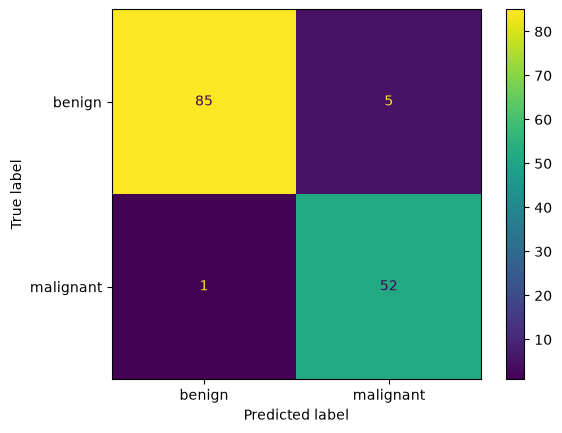

In [12]:
proba_test = best_model.predict_proba(X_test)[:, 1]
y_pred = (proba_test >= chosen_threshold).astype(int)

print(classification_report(y_test, y_pred, target_names=["benign", "malignant"], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["benign", "malignant"])
plt.show()

On the 143 test tumours, the model finds **52 of the 53 malignant ones** (recall 0.981) and raises 5 false alarms among the 90 benign ones (precision 0.912). That is in line with the cross-validated estimates from step 8, which is what we hoped: the test set confirms the choices instead of surprising us.

If this number had disappointed, it would be tempting to go back, change something and test again. Every time you do that, the test set becomes a little more like a validation set and its score a little more optimistic. That is why it comes last, once.

## 10. Interpret the model

An RBF SVM has no coefficients to read, but permutation importance works for any model: shuffle one feature in the test set and see how much the score drops.

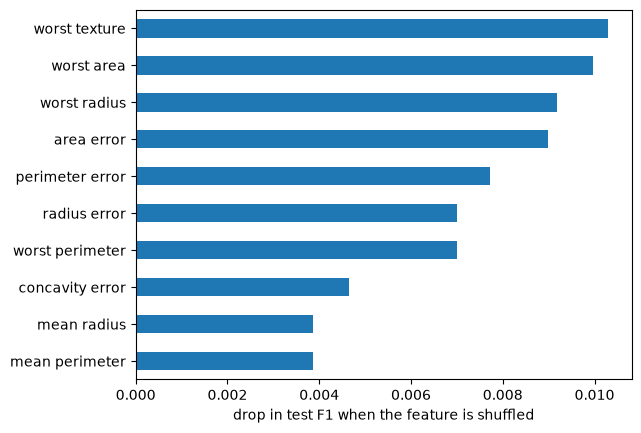

worst texture      0.010
worst area         0.010
worst radius       0.009
area error         0.009
perimeter error    0.008
dtype: float64

In [13]:
perm = permutation_importance(best_model, X_test, y_test, scoring="f1", n_repeats=20, random_state=0, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values()
importance.tail(10).plot.barh()
plt.xlabel("drop in test F1 when the feature is shuffled")
plt.show()
importance.sort_values(ascending=False).head(5).round(3)

No single feature matters much: shuffling the most important one lowers F1 by only about 0.01. The 30 measurements are highly redundant (radius, perimeter and area all describe the size of the nuclei), so when one is scrambled the model finds the same information in the others. The top of the list says the model relies mostly on **size** (`worst area`, `worst radius`, `area error`) and **texture**. To measure the importance of size as a whole, you would shuffle those related features together.

## 11. Save, reload and predict

The fitted pipeline contains everything needed to make a prediction: the scaler's means and standard deviations and the trained model. Saving the **whole pipeline** in one file means nobody can forget a preprocessing step, or apply it differently, when the model is used.

Before saving, it is common to refit the final pipeline on **all** the labelled data, training and test together: the settings are fixed, and more data usually gives a slightly better model. Its test score from step 9 remains the estimate to report.

In [14]:
final_model = search.best_estimator_.fit(X, y)
joblib.dump({"pipeline": final_model, "threshold": chosen_threshold}, "cancer_model.joblib")
print("Saved.")

Saved.


Anyone with the file, and the same scikit-learn version, can now load it and predict. New data must have the same columns as `X`. Here, two "new" tumours stand in for tomorrow's biopsies:

In [15]:
saved = joblib.load("cancer_model.joblib")
new_tumours = X_test.iloc[:2]                     # stand-ins for new patients

proba_new = saved["pipeline"].predict_proba(new_tumours)[:, 1]
for row, p in zip(new_tumours.index, proba_new):
    label = "malignant" if p >= saved["threshold"] else "benign"
    print(f"Tumour {row}: probability of malignancy {p:.3f} -> {label}")

Tumour 468: probability of malignancy 0.998 -> malignant
Tumour 221: probability of malignancy 0.005 -> benign


`joblib` is the format scikit-learn recommends; `pickle` works the same way. Only load model files you trust, because loading one can run code.

## Summary: the template

| Step | What to do | Typical code |
|---|---|---|
| 1. Frame | positive class, costly mistake, metric | `y = (target == "yes").astype(int)` |
| 2. Look | types, missing values, scales, target balance | `X.info()`, `X.describe()` |
| 3. Split once | stratified, test set put away | `train_test_split(..., stratify=y, random_state=0)` |
| 4. Baseline | the score to beat | `DummyClassifier()` |
| 5. Pipelines | preprocessing + model in one object | `make_pipeline(...)`, `ColumnTransformer` |
| 6. Compare | same folds, same metrics | `cross_validate(model, X_train, y_train, cv=cv, scoring=...)` |
| 7. Tune | the best one or two models | `GridSearchCV(pipe, [grid_1, grid_2], cv=cv)` |
| 8. Threshold | from cross-validated probabilities | `cross_val_predict(..., method="predict_proba")` |
| 9. Test once | report, confusion matrix | `classification_report(y_test, y_pred)` |
| 10. Interpret | what the model relies on | `permutation_importance(...)` |
| 11. Save | the whole pipeline | `joblib.dump(...)`, `joblib.load(...)` |

The page for today has the whole template in one block, ready to adapt.

## Appendix

### A.1 The same template with mixed column types

Real data mixes numbers, text categories and missing values. The only part of the template that changes is step 5: a `ColumnTransformer` sends each group of columns through its own preprocessing. Here it is on the churn data from Week 4 Day 5, keeping `State` as a category this time, and with a few values blanked out to show the imputers at work.

In [16]:
churn = pd.read_csv("data/churn.csv")
y_c = (churn["Churn?"] == "True.").astype(int)
X_c = churn.drop(columns=["Phone", "Churn?"])
X_c.loc[X_c.sample(frac=0.05, random_state=0).index, "Day Mins"] = np.nan      # simulate gaps
X_c.loc[X_c.sample(frac=0.05, random_state=1).index, "State"] = np.nan

categorical = ["State", "Int'l Plan", "VMail Plan"]
numeric = [col for col in X_c.columns if col not in categorical]

preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore")), categorical),
])

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_c, y_c, test_size=0.25, stratify=y_c, random_state=0)
for name, model in [("Logistic regression", LogisticRegression(max_iter=2000)),
                    ("Random forest", RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1))]:
    pipe_c = Pipeline([("prep", preprocess), ("model", model)])
    f1 = cross_val_score(pipe_c, Xc_train, yc_train, cv=cv, scoring="f1").mean()
    print(f"{name:<20} cross-validated F1 {f1:.3f}")

Logistic regression  cross-validated F1 0.322


Random forest        cross-validated F1 0.713


With the same preprocessing, logistic regression reaches an F1 of 0.322 and the random forest 0.713, consistent with Day 2: churn depends on combinations of features. The point here is the code: the `ColumnTransformer` imputes and scales the numbers, imputes and one-hot encodes the categories, and every one of those steps is refitted inside each fold. Steps 6 to 11 of the template work unchanged, because the whole thing is still one pipeline. `HistGradientBoostingClassifier` would not even need the imputers, since it handles missing values itself.

### A.2 Leakage: what goes wrong outside the pipeline

Steps that learn from data (scaling, imputing, selecting features) must be inside the pipeline. Here is a dramatic example: 200 rows of **pure noise**, 5,000 random features and random labels. No model can do better than 50% on this.

The leaky version picks the 20 features most correlated with the labels using all the rows, then cross-validates. The honest version does the same selection inside the pipeline, so it only sees the training folds.

In [17]:
rng = np.random.default_rng(0)
X_noise = rng.normal(size=(200, 5000))
y_noise = rng.integers(0, 2, size=200)

X_selected = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)     # looked at every row's label
leaky = cross_val_score(LogisticRegression(), X_selected, y_noise, cv=5).mean()

honest_pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression())
honest = cross_val_score(honest_pipe, X_noise, y_noise, cv=5).mean()

print(f"Selection before cross-validation: accuracy {leaky:.3f}")
print(f"Selection inside the pipeline:     accuracy {honest:.3f}")

Selection before cross-validation: accuracy 0.795
Selection inside the pipeline:     accuracy 0.510


On pure noise, the leaky version reports an accuracy of 0.795: a model that looks useful and is worthless. Selecting features with every row's label let the validation folds leak into the training. Inside the pipeline the score is 0.510, the coin flip it should be. With scaling the effect is usually small; with feature selection or target-based encodings it can be huge. Putting every data-dependent step in the pipeline removes the risk entirely.